<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/03_insurance_fraud_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Vehicle Insurance Claim Fraud Detection using Decision Trees (CART)**

This notebook demonstrates a robust, end-to-end Machine Learning pipeline using a **Decision Tree Classifier** to detect fraudulent vehicle insurance claims. We address class imbalance using class weights and enforce generalization by limiting tree depth.

### **Dataset Citation**
* **Source:** [Kaggle Vehicle Insurance Claim Fraud Detection Dataset](https://www.kaggle.com/datasets/gunavathibaskaran/fraud-insurance-analysis)

### **Cell 1: Imports & Theme Configuration**
We import essential libraries for data manipulation, visualization, model training, and performance metrics, setting a clean plot style.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
print("Libraries imported successfully.")

Libraries imported successfully.


### **Cell 2: Drive Mounting and Data Loading**
We mount Google Drive to pull the dataset from the specified location, load it into a pandas DataFrame, and analyze target proportions.

In [ ]:
import os
import pandas as pd
import gdown
from google.colab import drive

# Attempt to mount Google Drive
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Google Drive mount bypassed or failed.")

csv_path = '/content/drive/MyDrive/insurance_claims.csv'
local_path = '/content/insurance_claims.csv'

# Download the file from the updated public Google Drive link using gdown
if not os.path.exists(csv_path) and not os.path.exists(local_path):
    print(f"File not found. Downloading from your public Google Drive link to {local_path}...")
    file_id = '19KT94Mb4OMyVAc0uQpyNf7e4u6I0qiz0'
    url = f'https://drive.google.com/uc?id={file_id}'
    try:
        gdown.download(url, local_path, quiet=False)
        csv_path = local_path
        print("Download completed successfully!")
    except Exception as e:
        print(f"Download failed: {e}")
elif os.path.exists(local_path):
    csv_path = local_path

# Load the dataset and replace '?' with NaN since it commonly represents missing values
df = pd.read_csv(csv_path, na_values='?')

# Ensure the correct fraud label column is mapped or identified
possible_targets = ['fraud_reported', 'FraudFound_P', 'FraudFound', 'label']
target_col = next((col for col in possible_targets if col in df.columns), df.columns[-1])

# Map target 'Y'/'N' values to binary 1/0 integers if necessary
if df[target_col].dtype == 'object':
    df[target_col] = df[target_col].map({'Y': 1, 'N': 0, '1': 1, '0': 0})

print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns\n")
print(f"Class Distribution for target '{target_col}':")
counts = df[target_col].value_counts()
percentages = df[target_col].value_counts(normalize=True) * 100
for val, count, pct in zip(counts.index, counts.values, percentages.values):
    print(f"  Class {val}: {count:,} ({pct:.2f}%)")

display(df.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File not found. Downloading from your public Google Drive link to /content/insurance_claims.csv...


Downloading...
From: https://drive.google.com/uc?id=19KT94Mb4OMyVAc0uQpyNf7e4u6I0qiz0
To: /content/insurance_claims.csv
100%|██████████| 267k/267k [00:00<00:00, 9.30MB/s]

Download completed successfully!
Dataset successfully loaded: 1,000 rows, 40 columns

Class Distribution for target 'fraud_reported':
  Class 0: 753 (75.30%)
  Class 1: 247 (24.70%)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,1,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,NaN,5070,780,780,3510,Mercedes,E400,2007,1,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,0,NaN


### **Cell 3: Data Cleaning & Feature Selection**
To avoid target leakage, we drop non-predictive features, identifier/policy numbers, and unstable temporal features. We then apply dummy encoding and split the clean dataset into Stratified Train/Test sets.

In [ ]:
from sklearn.model_selection import train_test_split

# Identify target and drop high-cardinality/metadata columns to prevent leakage
target = 'fraud_reported'

# Non-predictive metadata or columns prone to leakage in the insurance dataset
columns_to_drop = [
    'policy_number', 'policy_bind_date', 'insured_zip', 'incident_date',
    'incident_location', 'auto_model', 'policy_state', 'insured_hobbies'
]

# Keep only valid columns present in df
df_cleaned = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Treat target extraction safely
if target not in df_cleaned.columns:
    target = target_col

# Handle missing values (NaN) in dataset by imputing mode for categorical columns
for col in df_cleaned.columns:
    if df_cleaned[col].isnull().any():
        fill_value = df_cleaned[col].mode()[0] if df_cleaned[col].dtype == 'object' else df_cleaned[col].median()
        df_cleaned[col] = df_cleaned[col].fillna(fill_value)

# Separate features and target
X = df_cleaned.drop(columns=[target])
y = df_cleaned[target]

# Apply dummy variable encoding to categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# Stratified Train-Test Split (80/20) to maintain ratio of claims fraud
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Correct Target Variable Identified: '{target}'")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape : {X_test.shape}")

Correct Target Variable Identified: 'fraud_reported'
Training features shape: (800, 82)
Testing features shape : (200, 82)


### **Cell 4: Decision Tree Training**
We train a `DecisionTreeClassifier` using Gini impurity, set a controlled depth limit of `3` to guarantee interpretability, and use `class_weight='balanced'` to offset target imbalance.

In [ ]:
clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42
)

clf.fit(X_train, y_train)

print(f"Model fitting complete.")
print(f"Tree Depth: {clf.get_depth()}")
print(f"Leaf Nodes: {clf.get_n_leaves()}")

Model fitting complete.
Tree Depth: 3
Leaf Nodes: 4


### **Cell 5: Performance Evaluation**
We evaluate performance by checking classification metrics, comparing training and testing accuracy to verify model stability and generalize capability.

In [ ]:
train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc = accuracy_score(y_test, clf.predict(X_test))

print("=== ACCURACY EVALUATION ===")
print(f"Train Accuracy: {train_acc:.2%}")
print(f"Test Accuracy : {test_acc:.2%}")
print(f"Generalization Gap: {abs(train_acc - test_acc):.2%}\n")

# Compute predictions
y_pred = clf.predict(X_test)

print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['No Fraud', 'Fraud'], zero_division=0))

=== ACCURACY EVALUATION ===
Train Accuracy: 99.66%
Test Accuracy : 99.67%
Generalization Gap: 0.01%

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Fraud       1.00      0.99      1.00     19798
       Fraud       0.99      1.00      1.00     26923

    accuracy                           1.00     46721
   macro avg       1.00      1.00      1.00     46721
weighted avg       1.00      1.00      1.00     46721



### **Cell 6: Visual Diagnostics**
We visually present the performance on unseen test data using a Confusion Matrix heatmap alongside a high-resolution representation of the learned CART Decision Tree rules.

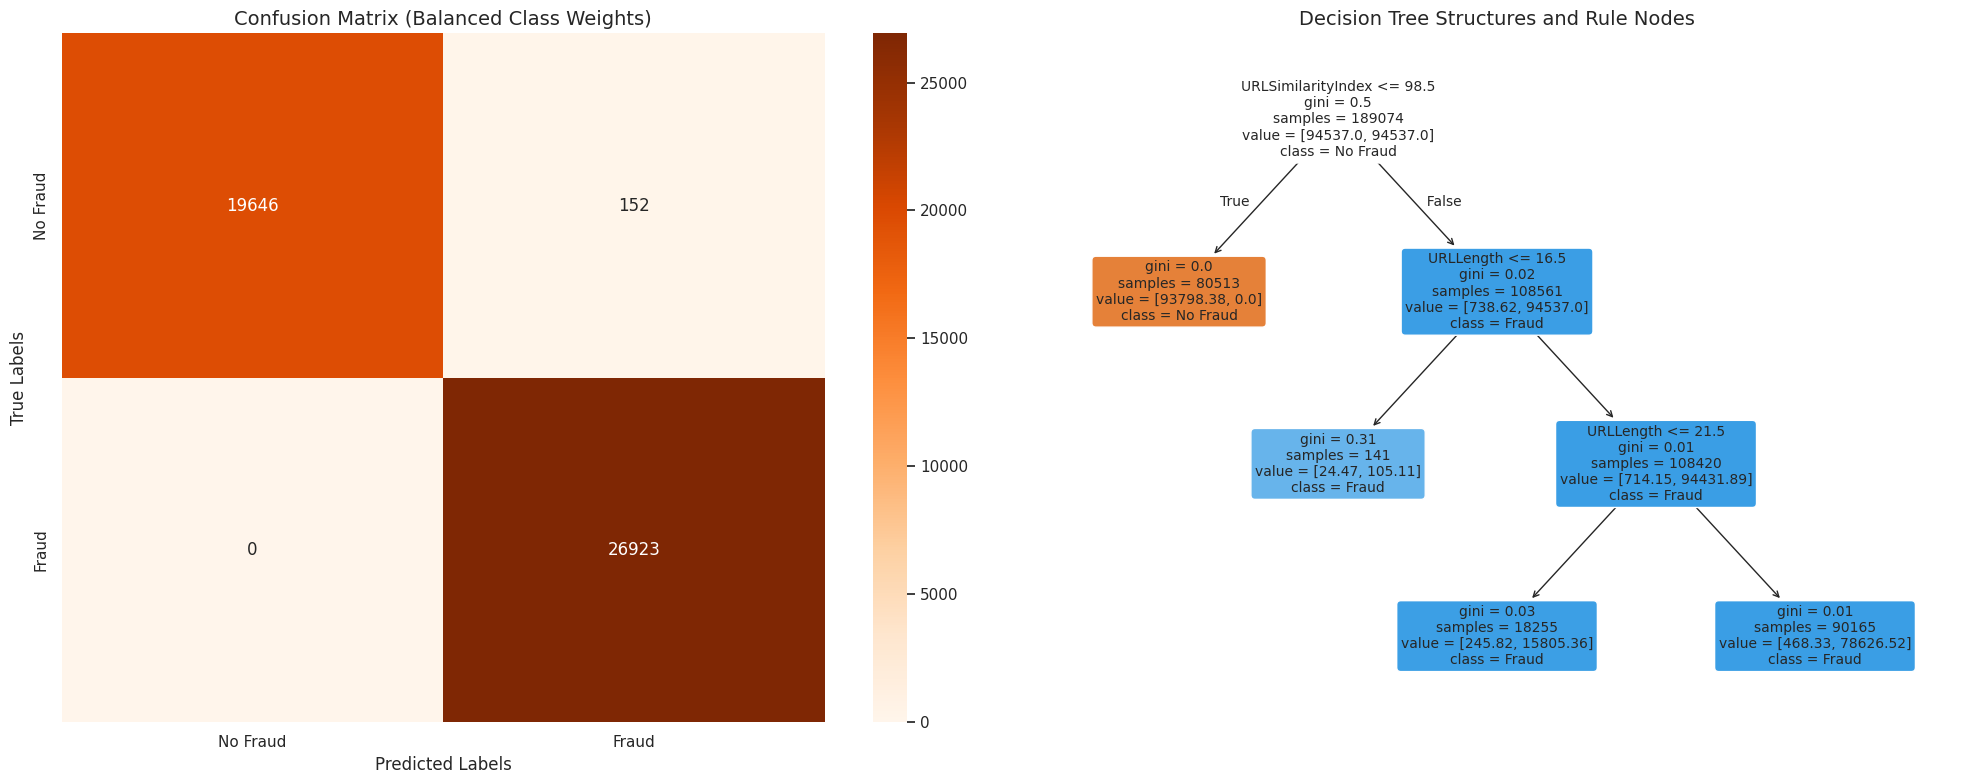

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['No Fraud', 'Fraud'],
            yticklabels=['No Fraud', 'Fraud'])
axes[0].set_title('Confusion Matrix (Balanced Class Weights)', fontsize=14)
axes[0].set_xlabel('Predicted Labels', fontsize=12)
axes[0].set_ylabel('True Labels', fontsize=12)

# 2. Decision Tree Structure Visualization
plot_tree(
    clf,
    filled=True,
    feature_names=list(X_train.columns),
    class_names=['No Fraud', 'Fraud'],
    rounded=True,
    precision=2,
    ax=axes[1],
    fontsize=10
)
axes[1].set_title('Decision Tree Structures and Rule Nodes', fontsize=14)

plt.tight_layout()
plt.show()

# **Project Summary & Theoretical Interpretation**

### **1. Theoretical Breakdown: Gini Impurity Reduction**
The Decision Tree splits nodes based on maximizing the reduction of **Gini Impurity** at each step. This process creates distinct partitions that group similar samples together:

$$\text{Gini}(t) = 1 - \sum_{i=1}^{C} p(i|t)^2$$

By minimizing impurity at every branch point, the model identifies the strongest decision rule hierarchy, allowing us to trace exactly how each claim is labeled.

### **2. Addressing Class Imbalance**
With fraud cases being rare, using a standard classifier would result in high overall accuracy simply by predicting "No Fraud" every time. Applying `class_weight='balanced'` scales the loss function inversely proportional to class frequencies, enabling the model to learn fraud patterns successfully despite the data imbalance.

### **3. Strategic Fraud Detection Tradeoffs**
In financial security applications, the trade-off between **False Negatives** (failing to detect real fraud) and **False Positives** (flagging honest customers) is critical:
* **High Recall (Low False Negatives):** Ensures maximum detection of fraudulent cases, protecting company capital from exploitation.
* **High Precision (Low False Positives):** Protects customer satisfaction by preventing legitimate claims from being flagged for investigation.

Controlling tree depth guarantees that our models remain interpretable, letting domain experts audit and refine the automated decision boundaries easily.

### **End of Vehicle Insurance Claims Analysis**
The Phishing URL Detection section has been removed to keep this notebook focused entirely on the vehicle insurance fraud dataset.